<a href="https://colab.research.google.com/github/priymakandrey-toothless/IAD_lab/blob/main/IAD_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Імпорт бібліотек та первинне очищення датасету

In [9]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, silhouette_score, adjusted_rand_score
)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# 1. Завантаження датасету
df = pd.read_csv('Obfuscated-MalMem2022.csv')
print(f"Завантажено рядків: {df.shape[0]}, стовпців: {df.shape[1]}")

# 2. Кодування цільової змінної y (Class)
le = LabelEncoder()
y = le.fit_transform(df['Class'].astype(str).str.strip())

print("\nРозподіл цільових класів у датасеті:")
for cls_name, count in zip(le.classes_, np.bincount(y)):
    print(f"  Клас '{cls_name}': {count} записів")

# Виділяємо також сімейство шкідливого ПЗ зі стовпця Category для глибшого аналізу візуалізацій
df['Malware_Family'] = df['Category'].apply(lambda x: str(x).split('-')[0])
print("\nРозподіл за категоріями/сімействами:")
print(df['Malware_Family'].value_counts())

# 3. Формування матриці ознак X
cols_to_drop = [c for c in ['Category', 'Class', 'Malware_Family'] if c in df.columns]
X_raw = df.drop(columns=cols_to_drop)

# Видаляємо константні стовпці (з нульовою дисперсією) та замінюємо можливі inf на nan
constant_cols = [c for c in X_raw.columns if X_raw[c].nunique() <= 1]
print(f"\nВидалено константні ознаки ({len(constant_cols)}): {constant_cols}")

X = X_raw.drop(columns=constant_cols).replace([np.inf, -np.inf], np.nan)
# Заповнення випадкових пропусків (якщо трапляються поодинокі NaN)
X = X.fillna(X.median())

print(f"Кількість підготовлених ознак для аналізу: {X.shape[1]}")

Завантажено рядків: 58596, стовпців: 57

Розподіл цільових класів у датасеті:
  Клас 'Benign': 29298 записів
  Клас 'Malware': 29298 записів

Розподіл за категоріями/сімействами:
Malware_Family
Benign        29298
Spyware       10020
Ransomware     9791
Trojan         9487
Name: count, dtype: int64

Видалено константні ознаки (3): ['pslist.nprocs64bit', 'handles.nport', 'svcscan.interactive_process_services']
Кількість підготовлених ознак для аналізу: 52


Масштабування, застосування PCA та порівняння класифікації «До» і «Після»

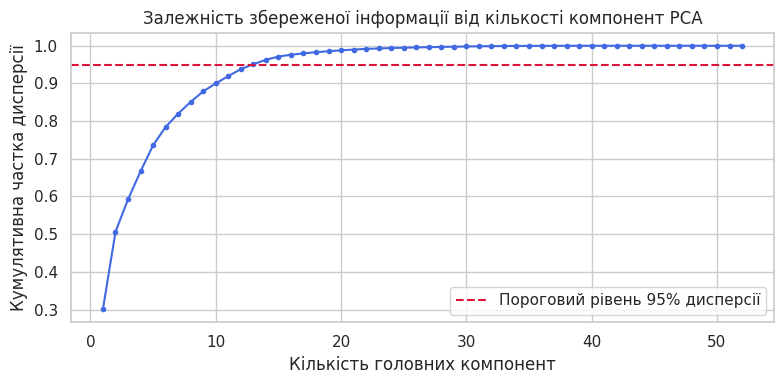

Кількість ознак ДО PCA: 52
Кількість компонент ПІСЛЯ PCA: 13
Стиснення розмірності: у 4.0 раза



,Етап,Accuracy,F1-Score,Час навчання (с),Час інференсу (с)
0,До PCA (52 ознак),0.99932,0.99932,3.73735,0.76258
1,Після PCA (13 компонент),0.99889,0.99889,2.19640,0.58081


In [10]:
# 1. Стратифіковане розбиття на train / test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Масштабування (fit виключно на тренувальній вибірці)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Аналіз кумулятивної поясненої дисперсії
pca_full = PCA(random_state=42).fit(X_train_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', markersize=3, color='royalblue')
plt.axhline(y=0.95, color='crimson', linestyle='--', label='Пороговий рівень 95% дисперсії')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна частка дисперсії')
plt.title('Залежність збереженої інформації від кількості компонент PCA')
plt.legend()
plt.tight_layout()
plt.show()

# 4. Трансформація PCA зі збереженням 95% дисперсії
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Кількість ознак ДО PCA: {X_train_scaled.shape[1]}")
print(f"Кількість компонент ПІСЛЯ PCA: {pca.n_components_}")
print(f"Стиснення розмірності: у {X_train_scaled.shape[1] / pca.n_components_:.1f} раза\n")

# 5. Класифікація ДО PCA (SVM з Lab 1)
clf_before = SVC(kernel='rbf', random_state=42)
t0 = time.perf_counter()
clf_before.fit(X_train_scaled, y_train)
t_train_before = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_before = clf_before.predict(X_test_scaled)
t_pred_before = time.perf_counter() - t0

# 6. Класифікація ПІСЛЯ PCA
clf_after = SVC(kernel='rbf', random_state=42)
t0 = time.perf_counter()
clf_after.fit(X_train_pca, y_train)
t_train_after = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_after = clf_after.predict(X_test_pca)
t_pred_after = time.perf_counter() - t0

# 7. Порівняльна таблиця результатів
results_pca = pd.DataFrame({
    'Етап': [f'До PCA ({X_train_scaled.shape[1]} ознак)', f'Після PCA ({pca.n_components_} компонент)'],
    'Accuracy': [accuracy_score(y_test, y_pred_before), accuracy_score(y_test, y_pred_after)],
    'F1-Score': [f1_score(y_test, y_pred_before), f1_score(y_test, y_pred_after)],
    'Час навчання (с)': [t_train_before, t_train_after],
    'Час інференсу (с)': [t_pred_before, t_pred_after]
})
display(results_pca.round(5))

Завдання 1: 2D-візуалізація простору ознак за допомогою t-SNE

Обчислення 2D проекції t-SNE


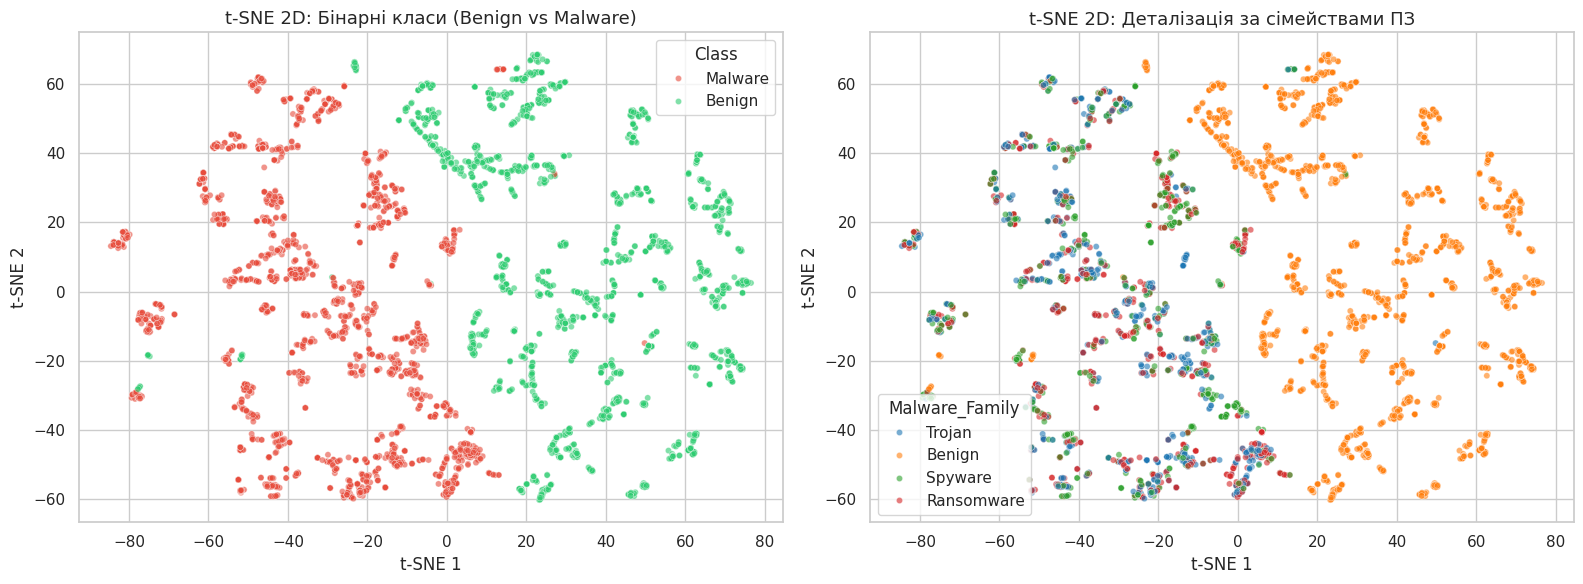

In [12]:
# Обираємо репрезентативну стратифіковану підвибірку 5000 рядків для швидкого та наочного t-SNE
df_sample, _ = train_test_split(
    df, train_size=5000, random_state=42, stratify=df['Malware_Family']
)

X_sample = df_sample.drop(columns=cols_to_drop + constant_cols).replace([np.inf, -np.inf], np.nan)
X_sample = X_sample.fillna(X_sample.median())
X_sample_scaled = StandardScaler().fit_transform(X_sample)

print("Обчислення 2D проекції t-SNE")
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_tsne_2d = tsne.fit_transform(X_sample_scaled)

# Візуалізація: зліва бінарні класи, справа конкретні сімейства
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    x=X_tsne_2d[:, 0], y=X_tsne_2d[:, 1],
    hue=df_sample['Class'], palette={'Benign': '#2ecc71', 'Malware': '#e74c3c'},
    alpha=0.6, s=20, ax=axes[0]
)
axes[0].set_title('t-SNE 2D: Бінарні класи (Benign vs Malware)', fontsize=13)
axes[0].set_xlabel('t-SNE 1')
axes[0].set_ylabel('t-SNE 2')

sns.scatterplot(
    x=X_tsne_2d[:, 0], y=X_tsne_2d[:, 1],
    hue=df_sample['Malware_Family'], palette='tab10',
    alpha=0.6, s=20, ax=axes[1]
)
axes[1].set_title('t-SNE 2D: Деталізація за сімействами ПЗ', fontsize=13)
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')

plt.tight_layout()
plt.show()

Завдання 2: Кластерний аналіз — підбір $k$ (Elbow Method та Silhouette Score)

Розрахунок метрик кластеризації K-Means...
k = 2 | Inertia: 2,308,379 | Silhouette Score: 0.3912
k = 3 | Inertia: 1,937,630 | Silhouette Score: 0.4441
k = 4 | Inertia: 1,732,650 | Silhouette Score: 0.4441
k = 5 | Inertia: 1,594,733 | Silhouette Score: 0.4570
k = 6 | Inertia: 1,430,591 | Silhouette Score: 0.4746
k = 7 | Inertia: 1,350,373 | Silhouette Score: 0.4841
k = 8 | Inertia: 1,204,836 | Silhouette Score: 0.4340


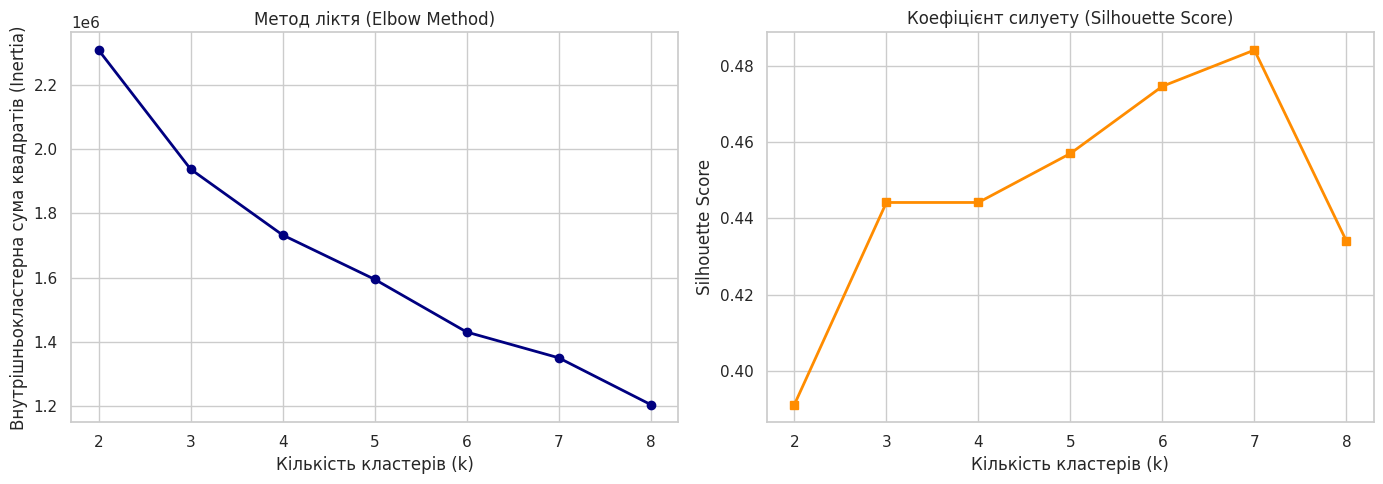

In [13]:
# Масштабуємо повний набір ознак
X_all_scaled = StandardScaler().fit_transform(X)

k_range = range(2, 9)
inertias = []
silhouettes = []

print("Розрахунок метрик кластеризації K-Means...")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_all_scaled)
    inertias.append(km.inertia_)
    # sample_size=10000 забезпечує швидкий та репрезентативний розрахунок силуету
    sil = silhouette_score(X_all_scaled, labels, sample_size=10000, random_state=42)
    silhouettes.append(sil)
    print(f"k = {k} | Inertia: {km.inertia_:,.0f} | Silhouette Score: {sil:.4f}")

# Графіки Elbow Method та Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, marker='o', color='navy', linewidth=2)
axes[0].set_title('Метод ліктя (Elbow Method)')
axes[0].set_xlabel('Кількість кластерів (k)')
axes[0].set_ylabel('Внутрішньокластерна сума квадратів (Inertia)')

axes[1].plot(k_range, silhouettes, marker='s', color='darkorange', linewidth=2)
axes[1].set_title('Коефіцієнт силуету (Silhouette Score)')
axes[1].set_xlabel('Кількість кластерів (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

Завдання 2: Фінальна кластеризація K-Means, 2D-візуалізація та порівняння з реальними класами

=== ЗІСТАВЛЕННЯ КЛАСТЕРІВ K-MEANS (k = 2) ТА СІМЕЙСТВ ДАТАСЕТУ ===
Кластер K-Means      0      1
Справжній Class              
Benign           25590   3708
Malware            143  29155
Adjusted Rand Index (ARI) для k=2: 0.7544

=== ЗІСТАВЛЕННЯ КЛАСТЕРІВ K-MEANS (k = 3) ТА СІМЕЙСТВ ДАТАСЕТУ ===
Кластер K-Means     0      1     2
Сімейство ПЗ                      
Benign           3953  24714   631
Ransomware        487      6  9298
Spyware           743     88  9189
Trojan            285     17  9185
Adjusted Rand Index (ARI) для k=3: 0.7820


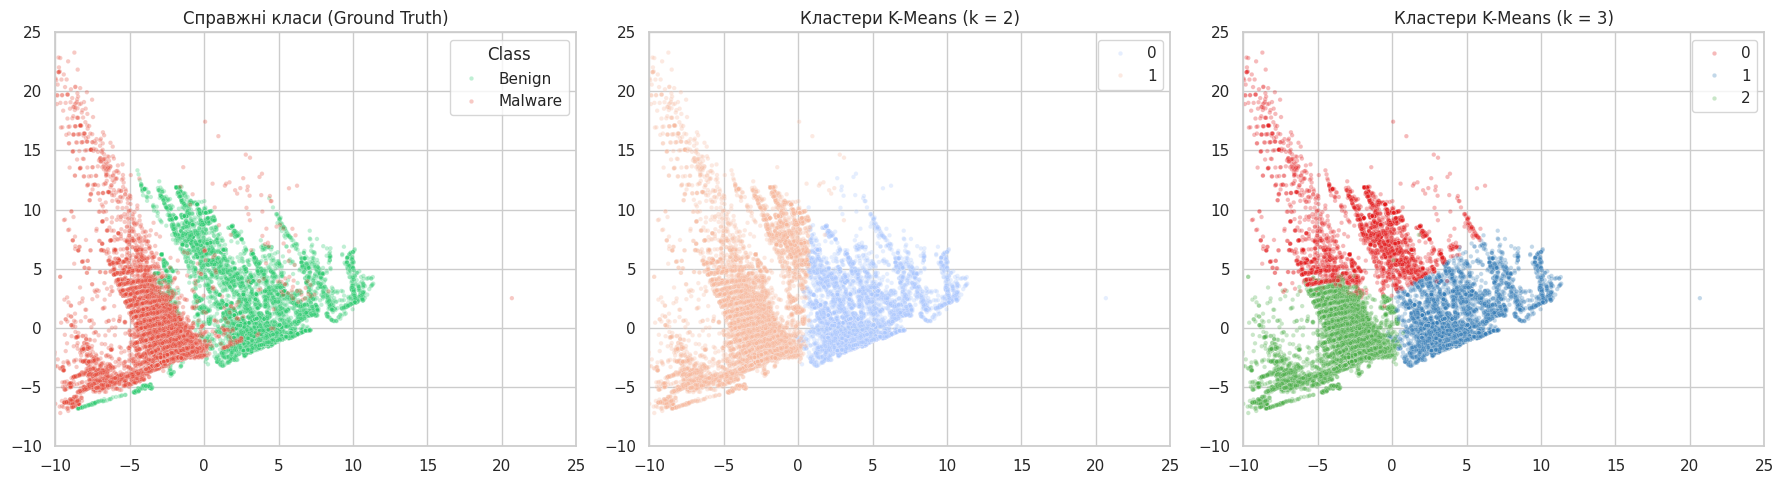

In [14]:
# 1. Кластеризація на k=2 (за кількістю бінарних класів) та k=3 (перелом ліктя / стрибок силуету)
km_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters_2 = km_2.fit_predict(X_all_scaled)

km_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_3 = km_3.fit_predict(X_all_scaled)

# 2. Таблиці зіставлення знайдених кластерів зі справжніми класами
print("=== ЗІСТАВЛЕННЯ КЛАСТЕРІВ K-MEANS (k = 2) ТА СІМЕЙСТВ ДАТАСЕТУ ===")
print(pd.crosstab(df['Class'], clusters_2, rownames=['Справжній Class'], colnames=['Кластер K-Means']))
print(f"Adjusted Rand Index (ARI) для k=2: {adjusted_rand_score(df['Class'], clusters_2):.4f}\n")

print("=== ЗІСТАВЛЕННЯ КЛАСТЕРІВ K-MEANS (k = 3) ТА СІМЕЙСТВ ДАТАСЕТУ ===")
print(pd.crosstab(df['Malware_Family'], clusters_3, rownames=['Сімейство ПЗ'], colnames=['Кластер K-Means']))
print(f"Adjusted Rand Index (ARI) для k=3: {adjusted_rand_score(df['Class'], clusters_3):.4f}")

# 3. Візуалізація результатів кластеризації у 2D через PCA
pca_vis = PCA(n_components=2, random_state=42)
X_vis_2d = pca_vis.fit_transform(X_all_scaled)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=X_vis_2d[:, 0], y=X_vis_2d[:, 1], hue=df['Class'],
                palette={'Benign': '#2ecc71', 'Malware': '#e74c3c'}, alpha=0.3, s=10, ax=axes[0])
axes[0].set_title('Справжні класи (Ground Truth)')
axes[0].set_xlim(-10, 25); axes[0].set_ylim(-10, 25)

sns.scatterplot(x=X_vis_2d[:, 0], y=X_vis_2d[:, 1], hue=clusters_2,
                palette='coolwarm', alpha=0.3, s=10, ax=axes[1])
axes[1].set_title('Кластери K-Means (k = 2)')
axes[1].set_xlim(-10, 25); axes[1].set_ylim(-10, 25)

sns.scatterplot(x=X_vis_2d[:, 0], y=X_vis_2d[:, 1], hue=clusters_3,
                palette='Set1', alpha=0.3, s=10, ax=axes[2])
axes[2].set_title('Кластери K-Means (k = 3)')
axes[2].set_xlim(-10, 25); axes[2].set_ylim(-10, 25)

plt.tight_layout()
plt.show()

Обробка та класифікація текстових даних

Завантаження текстів, очищення та побудова WordCloud для кожного класу

Успішно завантажено 44342 текстових документів.
Приклад очищеного тексту: immediate release april ...


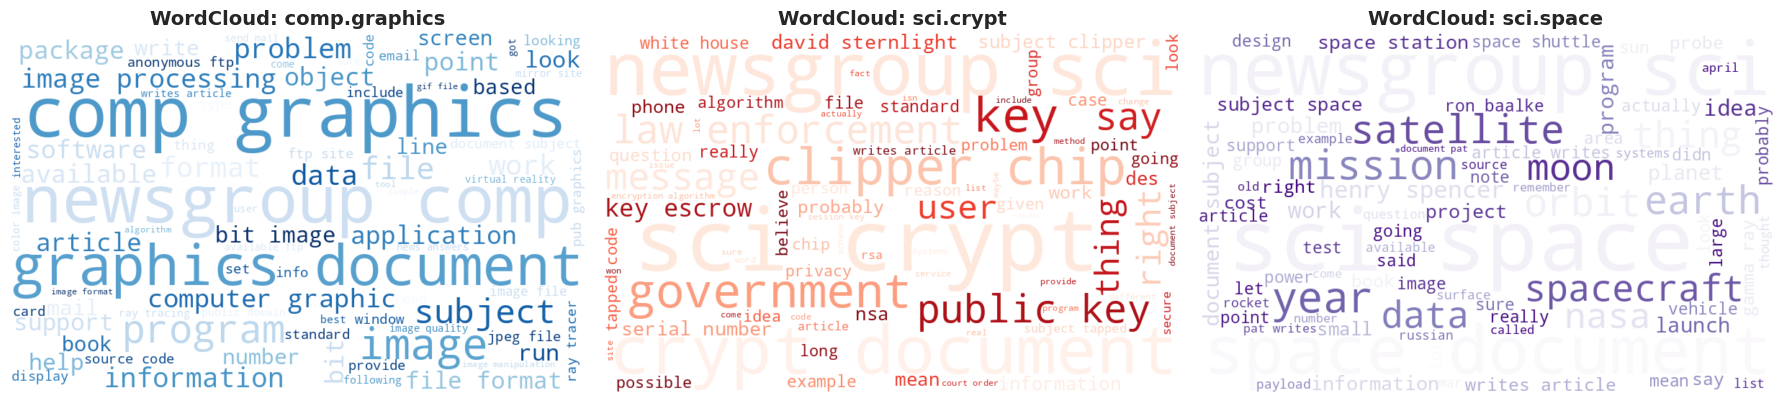

In [16]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

categories = ['comp.graphics', 'sci.crypt', 'sci.space']
raw_texts = []
labels = []
target_names = []

# 1. Читання текстів із завантажених файлів
for idx, category in enumerate(categories):
    # Шукаємо файл, у назві якого є ім'я категорії (наприклад, comp.graphics.txt)
    matching_files = [f for f in os.listdir('/content') if category in f]

    if not matching_files:
        print(f"⚠️ Файл для категорії '{category}' не знайдено у /content!")
        continue

    filepath = f"/content/{matching_files[0]}"
    target_names.append(category)

    # Зчитуємо дані залежно від формату
    if filepath.endswith('.csv'):
        df_text = pd.read_csv(filepath)
        col = 'text' if 'text' in df_text.columns else df_text.columns[0]
        docs = df_text[col].dropna().astype(str).tolist()
    else:
        with open(filepath, 'r', encoding='utf-8', errors='ignore') as f:
            content = f.read()
            # Розбиваємо суцільний текст на окремі повідомлення/абзаци
            docs = [t.strip() for t in content.split('\n\n') if len(t.strip()) > 50]

    raw_texts.extend(docs)
    labels.extend([idx] * len(docs))

print(f"Успішно завантажено {len(raw_texts)} текстових документів.")

# 2. Розбиття на train/test (оскільки ми читаємо з єдиних файлів)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    raw_texts, labels, test_size=0.2, random_state=42, stratify=labels
)

# 3. Передобробка текстів (видалення стоп-слів, символів, цифр)
custom_stopwords = set(ENGLISH_STOP_WORDS).union({
    'just', 'like', 'know', 'don', 'think', 'does', 'use', 'used', 'using',
    'good', 'time', 'people', 'make', 'way', 'need', 'want', 'new', 'edu', 'com', 'http', 'www'
})

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+|\S+@\S+', ' ', text)  # видаляємо посилання та email
    text = re.sub(r'[^a-z\s]', ' ', text)                  # залишаємо лише латинські літери
    tokens = [w for w in text.split() if w not in custom_stopwords and len(w) > 2]
    return " ".join(tokens)

X_train_clean = [preprocess_text(doc) for doc in X_train_raw]
X_test_clean = [preprocess_text(doc) for doc in X_test_raw]

print("Приклад очищеного тексту:", X_train_clean[0][:150], "...")

# 4. Візуалізація WordCloud для кожного класу
fig, axes = plt.subplots(1, len(target_names), figsize=(18, 6))
colormaps = ['Blues', 'Reds', 'Purples', 'Greens']

for idx, category_name in enumerate(target_names):
    # Збираємо всі очищені тексти поточного класу з тренувальної вибірки
    class_corpus = " ".join([X_train_clean[i] for i in range(len(X_train_clean)) if y_train[i] == idx])

    wc = WordCloud(
        width=800, height=500, background_color='white',
        colormap=colormaps[idx % len(colormaps)], max_words=80,
        collocations=True, random_state=42
    ).generate(class_corpus)

    axes[idx].imshow(wc, interpolation='bilinear')
    axes[idx].set_title(f"WordCloud: {category_name}", fontsize=14, fontweight='bold')
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

Векторизація текстів, навчання моделі та оцінка

Розмірність ознакового простору TF-IDF: 10000 унікальних слів/біграм

=== ЗВІТ ПРО КЛАСИФІКАЦІЮ ТЕКСТІВ ===
               precision    recall  f1-score   support

comp.graphics     0.9347    0.9724    0.9532      3371
    sci.crypt     0.9642    0.9461    0.9551      2877
    sci.space     0.9567    0.9267    0.9415      2621

     accuracy                         0.9504      8869
    macro avg     0.9519    0.9484    0.9499      8869
 weighted avg     0.9508    0.9504    0.9503      8869



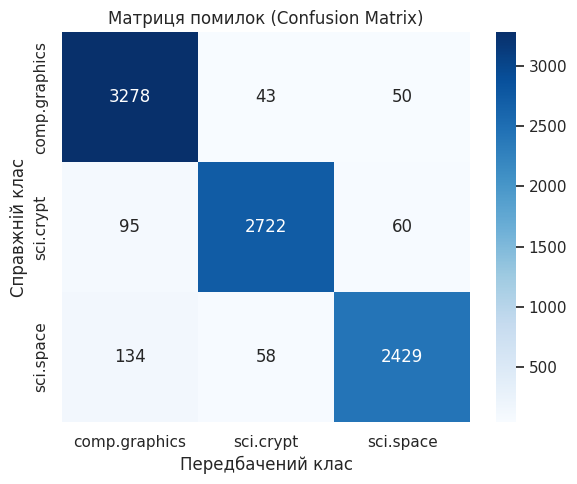

In [17]:
# 1. Векторизація текстів за допомогою TF-IDF (враховуємо слова та пари слів)
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),  # біграми допомагають виявити стійкі терміни, напр. "public key"
    min_df=3,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_clean)
X_test_tfidf = tfidf.transform(X_test_clean)

print(f"Розмірність ознакового простору TF-IDF: {X_train_tfidf.shape[1]} унікальних слів/біграм")

# 2. Навчання моделі логістичної регресії
text_clf = LogisticRegression(max_iter=1000, C=2.0, random_state=42)
text_clf.fit(X_train_tfidf, y_train)

# 3. Передбачення та оцінка метрик
y_pred = text_clf.predict(X_test_tfidf)

print("\n=== ЗВІТ ПРО КЛАСИФІКАЦІЮ ТЕКСТІВ ===")
print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

# 4. Матриця помилок
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=target_names, yticklabels=target_names
)
plt.title('Матриця помилок (Confusion Matrix)')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.tight_layout()
plt.show()